# Sentiment analysis on movie reviews

The question for this notebook: given the text of a movie review, can we tell whether the reviewer liked the film?

The data is NLTK's `movie_reviews` corpus, 2,000 IMDb reviews collected by Pang & Lee (2004) and labelled positive or negative. I'll work through it in steps:

1. load the corpus and take a first look
2. explore it: class balance, review lengths, the words people use
3. a lexicon baseline (VADER) that needs no training
4. bag-of-words and TF-IDF models
5. tuning and comparing them
6. looking at the reviews the best model still gets wrong

## 1. Setup and loading the data

In [1]:
import sys
from pathlib import Path

import nltk
import pandas as pd

# the helpers live in the repo root, next to this notebook
sys.path.insert(0, str(Path.cwd()))
from sentiment.data import load_reviews

pd.set_option("display.max_colwidth", 120)
print("nltk", nltk.__version__, "| pandas", pd.__version__)

nltk 3.10.4 | pandas 3.0.5


In [2]:
df = load_reviews()
print(df.shape)
df.head()

(2000, 3)


,fileid,label,text
0,neg/cv000_29416.txt,neg,"plot : two teen couples go to a church party , drink and then drive . \nthey get into an accident . \none of the guy..."
1,neg/cv001_19502.txt,neg,the happy bastard's quick movie review \ndamn that y2k bug . \nit's got a head start in this movie starring jamie le...
2,neg/cv002_17424.txt,neg,it is movies like these that make a jaded movie viewer thankful for the invention of the timex indiglo watch . \nbas...
3,neg/cv003_12683.txt,neg,""" quest for camelot "" is warner bros . ' first feature-length , fully-animated attempt to steal clout from disney's..."
4,neg/cv004_12641.txt,neg,synopsis : a mentally unstable man undergoing psychotherapy saves a boy from a potentially fatal accident and then f...


Each review is stored in its own file, and the file id already says which class it's in (`neg/cv000_29416.txt`). The label column comes from those folders, nothing was annotated by me.

In [3]:
df["label"].value_counts()

label
neg    1000
pos    1000
Name: count, dtype: int64

Exactly 1,000 of each, so accuracy is a fair metric here and a model that always guesses one class scores 50%. That's the floor every model has to beat.

What does a review actually look like?

In [4]:
sample = df.sample(2, random_state=7)
for _, row in sample.iterrows():
    print(f"[{row.label}] {row.fileid}")
    print(row.text[:700], "...\n")

[pos] pos/cv072_6169.txt
the long kiss goodnight ( r ) meryl streep tried it and failed . 
even pamela anderson lee made an attempt but fell flat on her well-bared assets . 
however , geena davis could very well become the first bankable american female action star with the long kiss goodnight , a preposterous but incredibly fun action thriller directed by her husband , renny harlin . 
davis plays samantha caine , a mousy suburban school teacher and mother whose memories only go back eight years . 
with the help of ethically questionable private detective mitch hennessey ( samuel l . jackson ) , she slowly remembers--and reclaims--her past as charly baltimore , tough-as-nails cia operative . 
needless to say , with  ...

[pos] pos/cv048_16828.txt
when _star wars_ came out some twenty years ago , the image of traveling throughout the stars has become a commonplace image . 
when the millenium falcon moves throughout the stars , we see constellations , meteor showers , and cool space-ship

A few things stand out already:

- the text is **lowercased and pre-tokenized**: punctuation is split off into its own tokens (`drive .`, `( r )`), so there's no capitalisation or formatting to use as a signal
- reviews are **long** and mostly plot summary; the actual opinion is often a couple of sentences, sometimes only at the end
- reviewers **mix praise and criticism** in one breath ("a preposterous but incredibly fun action thriller"), which will be hard for anything that just counts words

The corpus also comes with NLTK's own tokenization, which I'll use instead of splitting the raw text again:

In [5]:
from nltk.corpus import movie_reviews

words = movie_reviews.words(df.fileid[0])
print(len(words), "tokens in the first review")
print(words[:40])

879 tokens in the first review
['plot', ':', 'two', 'teen', 'couples', 'go', 'to', 'a', 'church', 'party', ',', 'drink', 'and', 'then', 'drive', '.', 'they', 'get', 'into', 'an', 'accident', '.', 'one', 'of', 'the', 'guys', 'dies', ',', 'but', 'his', 'girlfriend', 'continues', 'to', 'see', 'him', 'in', 'her', 'life', ',', 'and']


In [6]:
vocab = {w for fid in df.fileid for w in movie_reviews.words(fid)}
total_tokens = sum(len(movie_reviews.words(fid)) for fid in df.fileid)
print(f"{total_tokens:,} tokens, {len(vocab):,} distinct")

1,583,820 tokens, 39,768 distinct


Around 1.6 million tokens over 2,000 reviews, so about 790 per review on average. That's a lot more text per example than tweets or product one-liners, and the next section looks at how much the lengths vary.

## 2. Exploring the data

### Review lengths

Do positive and negative reviews differ in length? If one class were much longer, a model could pick that up instead of the actual sentiment, so it's worth checking before training anything.

In [7]:
import matplotlib.pyplot as plt
import numpy as np

from sentiment.data import ensure_corpus

ensure_corpus("punkt_tab", kind="tokenizers")  # .sents() splits sentences with punkt

df["tokens"] = [list(movie_reviews.words(fid)) for fid in df.fileid]
df["n_tokens"] = df["tokens"].str.len()
df["n_sentences"] = [len(movie_reviews.sents(fid)) for fid in df.fileid]

df.groupby("label")[["n_tokens", "n_sentences"]].describe().round(1).T

label                 neg     pos
n_tokens    count  1000.0  1000.0
            mean    751.3   832.6
            std     315.4   372.3
            min      19.0   144.0
            25%     543.0   575.8
            50%     707.0   779.5
            75%     905.2  1011.0
            max    2339.0  2879.0
n_sentences count  1000.0  1000.0
            mean     35.5    36.0
            std      18.8    16.6
            min       1.0     5.0
            25%      23.0    25.0
            50%      32.0    33.0
            75%      43.0    44.0
            max     188.0   127.0

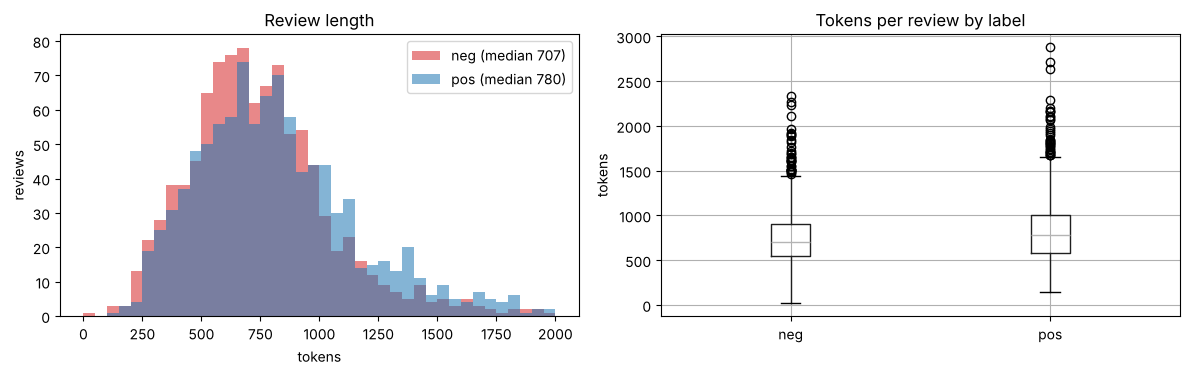

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 2000, 41)
for label, color in [("neg", "tab:red"), ("pos", "tab:blue")]:
    lengths = df.loc[df.label == label, "n_tokens"]
    name = f"{label} (median {lengths.median():.0f})"
    axes[0].hist(lengths, bins=bins, alpha=0.55, color=color, label=name)
axes[0].set(title="Review length", xlabel="tokens", ylabel="reviews")
axes[0].legend()

df.boxplot(column="n_tokens", by="label", ax=axes[1], showfliers=True)
axes[1].set(title="Tokens per review by label", xlabel="", ylabel="tokens")
fig.suptitle("")
plt.tight_layout()
plt.show()

In [9]:
from scipy.stats import mannwhitneyu

neg_len = df.loc[df.label == "neg", "n_tokens"]
pos_len = df.loc[df.label == "pos", "n_tokens"]
result = mannwhitneyu(pos_len, neg_len)
print(f"median tokens: pos {pos_len.median():.0f}, neg {neg_len.median():.0f}")
print(f"Mann-Whitney U p-value: {result.pvalue:.2g}")

median tokens: pos 780, neg 707
Mann-Whitney U p-value: 2.9e-06


Positive reviews run a bit longer: a median of about 780 tokens against 707 for negative ones, and the gap is
very unlikely to be chance (Mann-Whitney p ≈ 3e-6). Sentence counts are almost identical, so the difference comes
from longer sentences rather than more of them. The distributions overlap heavily though, so length on its own
would be a weak feature. It's a hint that reviewers who liked a film say more about it, not something a model
can lean on.

### Most common words

Raw counts first, then with English stopwords and punctuation removed.

In [10]:
from collections import Counter

from nltk.corpus import stopwords

ensure_corpus("stopwords")
stop = set(stopwords.words("english"))


def content_words(tokens):
    return [t for t in tokens if t.isalpha() and t not in stop]


raw_counts = Counter(t for toks in df.tokens for t in toks)
content_counts = {label: Counter() for label in ("neg", "pos")}
for label, toks in zip(df.label, df.tokens, strict=True):
    content_counts[label].update(content_words(toks))

pd.DataFrame({
    "raw": [w for w, _ in raw_counts.most_common(15)],
    "neg (content)": [w for w, _ in content_counts["neg"].most_common(15)],
    "pos (content)": [w for w, _ in content_counts["pos"].most_common(15)],
})

,raw,neg (content),pos (content)
0,",",film,film
1,the,movie,one
2,.,one,movie
3,a,like,like
4,and,even,good
5,of,time,story
6,to,good,time
7,',would,also
8,is,get,even
9,in,bad,well


### Words that separate the classes

Raw frequency mostly surfaces words both classes share ("film", "movie"). To find words that lean one way I use
the log-odds ratio with an informative Dirichlet prior (Monroe, Colaresi & Quinn 2008), which shrinks the scores
of rare words instead of letting a word seen twice dominate. Positive z-scores lean positive.

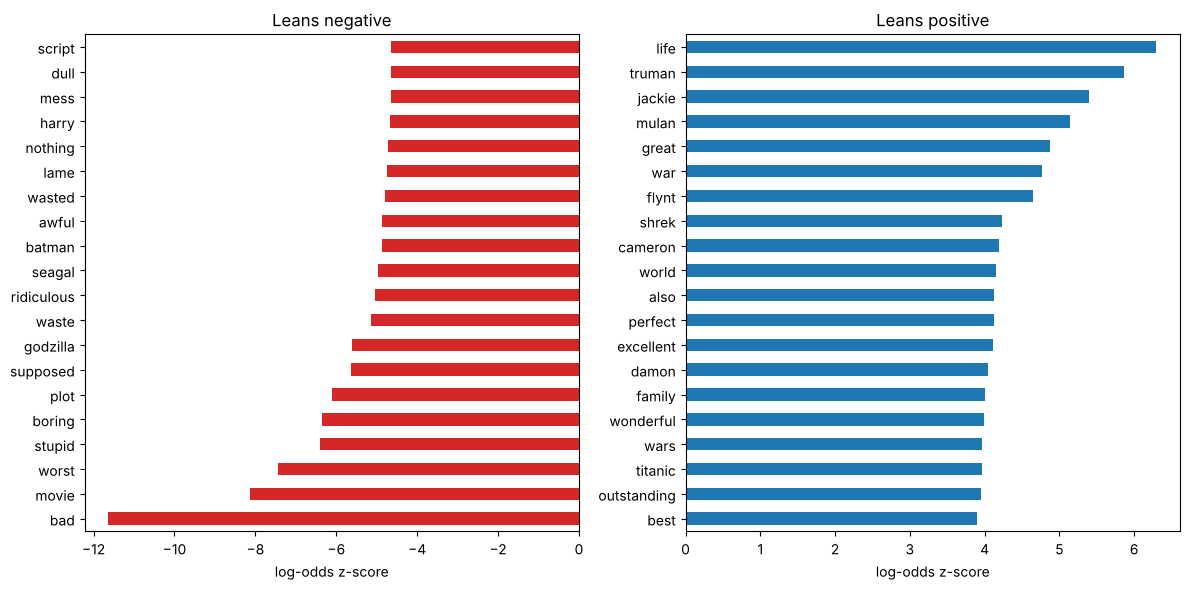

In [11]:
def log_odds(counts_a, counts_b, prior):
    a0, b0, p0 = sum(counts_a.values()), sum(counts_b.values()), sum(prior.values())
    rows = []
    for w, pw in prior.items():
        ya, yb = counts_a[w], counts_b[w]
        la = np.log((ya + pw) / (a0 + p0 - ya - pw))
        lb = np.log((yb + pw) / (b0 + p0 - yb - pw))
        var = 1 / (ya + pw) + 1 / (yb + pw)
        rows.append((w, (la - lb) / np.sqrt(var), ya, yb))
    return pd.DataFrame(rows, columns=["word", "z", "pos_count", "neg_count"]).set_index("word")


prior = content_counts["neg"] + content_counts["pos"]
scores = log_odds(content_counts["pos"], content_counts["neg"], prior).sort_values("z")
top_neg, top_pos = scores.head(20), scores.tail(20)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
top_neg.z.plot.barh(ax=axes[0], color="tab:red", title="Leans negative")
top_pos.z.plot.barh(ax=axes[1], color="tab:blue", title="Leans positive")
for ax in axes:
    ax.set(xlabel="log-odds z-score", ylabel="")
plt.tight_layout()
plt.show()

In [12]:
pd.concat([top_neg.head(10), top_pos.tail(10)[::-1]]).round(1)

,z,pos_count,neg_count
word,,,
bad,-11.6,361,1034
movie,-8.1,2525,3246
worst,-7.4,49,259
stupid,-6.4,45,208
boring,-6.3,52,218
plot,-6.1,596,917
supposed,-5.6,83,240
godzilla,-5.6,14,120
waste,-5.1,22,121


A few things stand out:

- With stopwords gone, the top of both lists is nearly the same ("film", "movie", "one", "like"), and "good" shows
  up high for negative reviews too (its z-score is about -0.7, so it is neutral). Frequency alone won't separate the classes.
- The negative side of the log-odds chart is clean sentiment vocabulary: "bad" (z ≈ -11.6, used about three times
  as often in negative reviews), "worst", "stupid", "boring", "waste", "ridiculous".
- "movie" leans negative (z ≈ -8.1) while "film" leans slightly positive (z ≈ 2.3). My guess is that people who
  dislike something call it a movie.
- The positive side is messier. Next to "great" and "life" it's full of titles and names: "truman", "mulan",
  "flynt", "shrek". Those films were well liked and reviewed more than once, so a bag-of-words model will learn
  "mentions Shrek → positive". That works on this corpus and generalises badly, which is worth remembering when
  the baseline scores come in.
- Negation is invisible here: "not good" counts as one "good". Handling that is one reason to try bigrams later.